# Using Multiple Collections

This tutorial shows how to create a data cube from multiple collections with `cubo`. The collections can come from the same STAC Catalogue, from different STAC Catalogues, and even from Google Earth Engine (GEE). All collections share the same pixel grid, so the cubes are co-registered by design.

In [1]:
import cubo
import ee
import matplotlib.pyplot as plt
import numpy as np

Initialize the high volume endpoint from Google Earth Engine (only required if you use GEE collections):

In [2]:
ee.Initialize(opt_url='https://earthengine-highvolume.googleapis.com')

When requesting multiple collections, consider the following things:

- Set `collection` to a list of collections.
- Set `bands` to a dictionary with collections as keys and the band(s) of each collection as values (collections not in the dictionary use all bands).
- If the collections come from different catalogues, set `stac` to a dictionary with endpoints as keys and the collection(s) of each endpoint as values. Use the `"ee"` key for GEE collections.
- The `resolution` is shared by all collections.

> **Note:** The `end_date` is included for both STAC Catalogues and GEE.

## Example 1: Merge collections from the same STAC Catalogue

Let's create a cube with Sentinel-2 L2A and Sentinel-1 RTC from Planetary Computer (the default `stac`):

In [3]:
da = cubo.create(
    lat=51.3397,
    lon=12.3731,
    collection=["sentinel-2-l2a", "sentinel-1-rtc"], # List of collections
    bands={"sentinel-2-l2a": ["B04", "B08"], "sentinel-1-rtc": ["vv", "vh"]}, # Bands of each collection
    start_date="2022-06-01",
    end_date="2022-06-15",
    edge_size=64,
    resolution=10,
)
da

<xarray.DataArray (time: 49, band: 4, y: 64, x: 64)> Size: 6MB
dask.array<concatenate, shape=(49, 4, 64, 64), dtype=float64, chunksize=(1, 1, 64, 64), chunktype=numpy.ndarray>
Coordinates:
  * time                       (time) datetime64[ns] 392B 2022-06-01T05:25:57...
  * band                       (band) <U3 48B 'B04' 'B08' 'vv' 'vh'
    collection                 (band) <U14 224B 'sentinel-2-l2a' ... 'sentine...
  * y                          (y) float64 512B 5.691e+06 ... 5.691e+06
  * x                          (x) float64 512B 3.167e+05 ... 3.173e+05
    cubo:distance_from_center  (y, x) float64 33kB 450.2 443.1 ... 433.8 440.8
Attributes:
    collection:           ['sentinel-2-l2a', 'sentinel-1-rtc']
    stac:                 ['https://planetarycomputer.microsoft.com/api/stac/...
    epsg:                 32633
    resolution:           10
    edge_size:            64
    edge_size_m:          640
    central_lat:          51.3397
    central_lon:          12.3731
    central_y:            5690878.11673681
    central_x:            317034.7504518318
    time_coverage_start:  2022-06-01
    time_coverage_end:    2022-06-15

By default, the cubes are merged along the `band` dimension, and the `time` dimension is the union of the timestamps of all collections (with NaN where a collection has no data). The `collection` coordinate tells you where each band comes from:

In [4]:
da.collection

<xarray.DataArray 'collection' (band: 4)> Size: 224B
array(['sentinel-2-l2a', 'sentinel-2-l2a', 'sentinel-1-rtc',
       'sentinel-1-rtc'], dtype='<U14')
Coordinates:
  * band        (band) <U3 48B 'B04' 'B08' 'vv' 'vh'
    collection  (band) <U14 224B 'sentinel-2-l2a' ... 'sentinel-1-rtc'

> **Note:** Metadata coordinates of each collection (e.g., `eo:cloud_cover`) are dropped when merging, and bands with the same name in multiple collections cannot be merged. Use `datatree=True` in those cases.

## Example 2: Use a DataTree

Different collections rarely share timestamps. With `datatree=True`, `cubo` returns a `xr.DataTree` with one node per collection: each node keeps its own `time` and `band` dimensions (and metadata), while the spatial coordinates are shared:

In [5]:
dt = cubo.create(
    lat=51.3397,
    lon=12.3731,
    collection=["sentinel-2-l2a", "sentinel-1-rtc"],
    bands={"sentinel-2-l2a": ["B04", "B08"], "sentinel-1-rtc": ["vv", "vh"]},
    start_date="2022-06-01",
    end_date="2022-06-15",
    edge_size=64,
    resolution=10,
    datatree=True, # Return a DataTree
)
dt

<xarray.DataTree>
Group: /
│   Dimensions:                    (y: 64, x: 64)
│   Coordinates:
│     * y                          (y) float64 512B 5.691e+06 ... 5.691e+06
│     * x                          (x) float64 512B 3.167e+05 ... 3.173e+05
│       cubo:distance_from_center  (y, x) float64 33kB 450.2 443.1 ... 433.8 440.8
│   Attributes:
│       epsg:                 32633
│       resolution:           10
│       edge_size:            64
│       edge_size_m:          640
│       central_lat:          51.3397
│       central_lon:          12.3731
│       central_y:            5690878.11673681
│       central_x:            317034.7504518318
│       time_coverage_start:  2022-06-01
│       time_coverage_end:    2022-06-15
├── Group: /sentinel-2-l2a
│       Dimensions:                                  (time: 44, band: 2, y: 64, x: 64)
│       Coordinates: (12/42)
│         * time                                     (time) datetime64[ns] 352B 2022-...
│           id                                       (time) <U54 10kB 'S2B_MSIL2A_202...
│           s2:processing_baseline                   (time) <U5 880B '05.10' ... '04.00'
│           proj:code                                (time) <U10 2kB 'EPSG:32633' ......
│           s2:water_percentage                      (time) float64 352B 0.4361 ... 0...
│           s2:mean_solar_zenith                     (time) float64 352B 31.16 ... 28.83
│           ...                                       ...
│           constellation                            <U10 40B 'Sentinel 2'
│           instruments                              <U3 12B 'msi'
│           s2:product_type                          <U7 28B 'S2MSI2A'
│           gsd                                      int64 8B 10
│           proj:shape                               object 8B {10980}
│           epsg                                     int64 8B 32633
│       Data variables:
│           data                                     (time, band, y, x) float64 3MB dask.array<chunksize=(1, 1, 64, 64), meta=np.ndarray>
│       Attributes:
│           collection:           sentinel-2-l2a
│           stac:                 https://planetarycomputer.microsoft.com/api/stac/v1
│           epsg:                 32633
│           resolution:           10
│           edge_size:            64
│           edge_size_m:          640
│           central_lat:          51.3397
│           central_lon:          12.3731
│           central_y:            5690878.11673681
│           central_x:            317034.7504518318
│           time_coverage_start:  2022-06-01
│           time_coverage_end:    2022-06-15
└── Group: /sentinel-1-rtc
        Dimensions:                                (time: 5, band: 2, y: 64, x: 64)
        Coordinates: (12/37)
          * time                                   (time) datetime64[ns] 40B 2022-06-...
            id                                     (time) <U66 1kB 'S1A_IW_GRDH_1SDV_...
            start_datetime                         (time) <U32 640B '2022-06-01 05:25...
            sat:orbit_state                        (time) <U10 200B 'descending' ... ...
            s1:total_slices                        (time) <U2 40B '30' '28' ... '30'
            s1:datatake_id                         (time) <U6 120B '340129' ... '341458'
            ...                                     ...
            s1:product_timeliness                  <U6 24B 'NRT-3h'
            sar:observation_direction              <U5 20B 'right'
            platform                               <U11 44B 'SENTINEL-1A'
            s1:orbit_source                        <U6 24B 'PREORB'
            raster:bands                           object 8B {'nodata': -32768, 'data...
            epsg                                   int64 8B 32633
        Data variables:
            data                                   (time, band, y, x) float64 328kB dask.array<chunksize=(1, 1, 64, 64), meta=np.ndarray>
        Attributes:
            collection:     

Each node contains the cube as the `data` variable:

In [6]:
dt["sentinel-1-rtc"]["data"]

<xarray.DataArray 'data' (time: 5, band: 2, y: 64, x: 64)> Size: 328kB
dask.array<fetch_raster_window, shape=(5, 2, 64, 64), dtype=float64, chunksize=(1, 1, 64, 64), chunktype=numpy.ndarray>
Coordinates: (12/39)
  * time                                   (time) datetime64[ns] 40B 2022-06-...
    id                                     (time) <U66 1kB 'S1A_IW_GRDH_1SDV_...
    start_datetime                         (time) <U32 640B '2022-06-01 05:25...
    sat:orbit_state                        (time) <U10 200B 'descending' ... ...
    s1:total_slices                        (time) <U2 40B '30' '28' ... '30'
    s1:datatake_id                         (time) <U6 120B '340129' ... '341458'
    ...                                     ...
    s1:product_timeliness                  <U6 24B 'NRT-3h'
    sar:observation_direction              <U5 20B 'right'
    platform                               <U11 44B 'SENTINEL-1A'
    s1:orbit_source                        <U6 24B 'PREORB'
    raster:bands                           object 8B {'nodata': -32768, 'data...
    epsg                                   int64 8B 32633
Attributes:
    collection:           sentinel-1-rtc
    stac:                 https://planetarycomputer.microsoft.com/api/stac/v1
    epsg:                 32633
    resolution:           10
    edge_size:            64
    edge_size_m:          640
    central_lat:          51.3397
    central_lon:          12.3731
    central_y:            5690878.11673681
    central_x:            317034.7504518318
    time_coverage_start:  2022-06-01
    time_coverage_end:    2022-06-15

## Example 3: Combine STAC and GEE

Now let's combine Sentinel-2 L2A from Planetary Computer with the Sentinel-2 Cloud Probability from GEE. Set `stac` to a dictionary and use the `"ee"` key for GEE collections:

In [7]:
dt = cubo.create(
    lat=51.3397,
    lon=12.3731,
    collection=["sentinel-2-l2a", "COPERNICUS/S2_CLOUD_PROBABILITY"],
    bands={"sentinel-2-l2a": ["B02", "B03", "B04"], "COPERNICUS/S2_CLOUD_PROBABILITY": "probability"},
    stac={
        "https://planetarycomputer.microsoft.com/api/stac/v1": "sentinel-2-l2a",
        "ee": "COPERNICUS/S2_CLOUD_PROBABILITY", # GEE collection
    },
    start_date="2022-06-14",
    end_date="2022-06-17",
    edge_size=128,
    resolution=10,
    datatree=True,
)
dt

<xarray.DataTree>
Group: /
│   Dimensions:                    (y: 128, x: 128)
│   Coordinates:
│     * y                          (y) float64 1kB 5.692e+06 5.692e+06 ... 5.69e+06
│     * x                          (x) float64 1kB 3.164e+05 3.164e+05 ... 3.177e+05
│       cubo:distance_from_center  (y, x) float64 131kB 902.7 895.7 ... 886.3 893.3
│   Attributes:
│       epsg:                 32633
│       resolution:           10
│       edge_size:            128
│       edge_size_m:          1280
│       central_lat:          51.3397
│       central_lon:          12.3731
│       central_y:            5690878.11673681
│       central_x:            317034.7504518318
│       time_coverage_start:  2022-06-14
│       time_coverage_end:    2022-06-17
├── Group: /sentinel-2-l2a
│       Dimensions:                                  (time: 16, band: 3, y: 128, x: 128)
│       Coordinates: (12/42)
│         * time                                     (time) datetime64[ns] 128B 2022-...
│           id                                       (time) <U54 3kB 'S2B_MSIL2A_2022...
│           s2:processing_baseline                   (time) <U5 320B '05.10' ... '04.00'
│           proj:code                                (time) <U10 640B 'EPSG:32633' .....
│           s2:water_percentage                      (time) float64 128B 0.7722 ... 1...
│           s2:mean_solar_zenith                     (time) float64 128B 29.67 ... 29.41
│           ...                                       ...
│           constellation                            <U10 40B 'Sentinel 2'
│           instruments                              <U3 12B 'msi'
│           s2:product_type                          <U7 28B 'S2MSI2A'
│           gsd                                      int64 8B 10
│           proj:shape                               object 8B {10980}
│           epsg                                     int64 8B 32633
│       Data variables:
│           data                                     (time, band, y, x) float64 6MB dask.array<chunksize=(1, 1, 128, 128), meta=np.ndarray>
│       Attributes:
│           collection:           sentinel-2-l2a
│           stac:                 https://planetarycomputer.microsoft.com/api/stac/v1
│           epsg:                 32633
│           resolution:           10
│           edge_size:            128
│           edge_size_m:          1280
│           central_lat:          51.3397
│           central_lon:          12.3731
│           central_y:            5690878.11673681
│           central_x:            317034.7504518318
│           time_coverage_start:  2022-06-14
│           time_coverage_end:    2022-06-17
└── Group: /COPERNICUS
    └── Group: /COPERNICUS/S2_CLOUD_PROBABILITY
            Dimensions:  (time: 8, band: 1, y: 128, x: 128)
            Coordinates:
              * time     (time) datetime64[ns] 64B 2022-06-15T10:15:59 ... 2022-06-17T10:...
              * band     (band) object 8B 'probability'
            Data variables:
                data     (time, band, y, x) float32 524kB dask.array<chunksize=(8, 1, 128, 128), meta=np.ndarray>
            Attributes:
                collection:           COPERNICUS/S2_CLOUD_PROBABILITY
                stac:                 https://earthengine-stac.storage.googleapis.com/cat...
                epsg:                 32633
                resolution:           10
                edge_size:            128
                edge_size_m:          1280
                central_lat:          51.3397
                central_lon:          12.3731
                central_y:            5690878.11673681
                central_x:            317034.7504518318
                time_coverage_start:  2022-06-14
                time_coverage_end:    2022-06-17

GEE collection IDs contain `/`, so they are stored as nested nodes, and you can access them with the same ID:

In [8]:
dt["COPERNICUS/S2_CLOUD_PROBABILITY"]["data"]

<xarray.DataArray 'data' (time: 8, band: 1, y: 128, x: 128)> Size: 524kB
dask.array<transpose, shape=(8, 1, 128, 128), dtype=float32, chunksize=(8, 1, 128, 128), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 64B 2022-06-15T10:15:59 ... 2022-06-17T10:...
  * band     (band) object 8B 'probability'
  * y        (y) float64 1kB 5.692e+06 5.692e+06 5.692e+06 ... 5.69e+06 5.69e+06
  * x        (x) float64 1kB 3.164e+05 3.164e+05 ... 3.176e+05 3.177e+05
Attributes:
    collection:           COPERNICUS/S2_CLOUD_PROBABILITY
    stac:                 https://earthengine-stac.storage.googleapis.com/cat...
    epsg:                 32633
    resolution:           10
    edge_size:            128
    edge_size_m:          1280
    central_lat:          51.3397
    central_lon:          12.3731
    central_y:            5690878.11673681
    central_x:            317034.7504518318
    time_coverage_start:  2022-06-14
    time_coverage_end:    2022-06-17

Both cubes share the same pixel grid, so we can compare them directly:

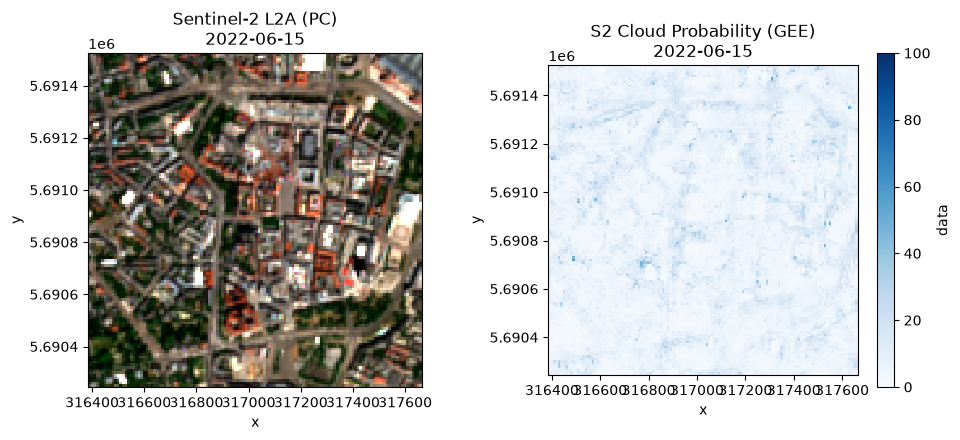

In [9]:
rgb = dt["sentinel-2-l2a"]["data"].isel(time=0).sel(band=["B04", "B03", "B02"])
probability = dt["COPERNICUS/S2_CLOUD_PROBABILITY"]["data"].isel(time=0, band=0)

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
rgb.plot.imshow(ax=ax[0], robust=True)
probability.plot.imshow(ax=ax[1], cmap="Blues", vmin=0, vmax=100)
ax[0].set_title(f"Sentinel-2 L2A (PC)\n{str(rgb.time.values)[:10]}")
ax[1].set_title(f"S2 Cloud Probability (GEE)\n{str(probability.time.values)[:10]}")
for a in ax:
    a.set_aspect("equal")
plt.tight_layout()

## Example 4: Use Datasets

Use `dataset=True` to get a `xr.Dataset` with one variable per band instead of a `xr.DataArray`. This also works for single collections, merged collections, and the nodes of a DataTree:

In [10]:
dt = cubo.create(
    lat=51.3397,
    lon=12.3731,
    collection=["sentinel-2-l2a", "sentinel-1-rtc"],
    bands={"sentinel-2-l2a": ["B04", "B08"], "sentinel-1-rtc": ["vv", "vh"]},
    start_date="2022-06-01",
    end_date="2022-06-15",
    edge_size=64,
    resolution=10,
    datatree=True,
    dataset=True, # One variable per band
)
dt["sentinel-2-l2a"]

<xarray.DataTree 'sentinel-2-l2a'>
Group: /sentinel-2-l2a
    Dimensions:                                  (y: 64, x: 64, time: 44, band: 2)
    Coordinates: (12/41)
      * time                                     (time) datetime64[ns] 352B 2022-...
        id                                       (time) <U54 10kB 'S2B_MSIL2A_202...
        s2:processing_baseline                   (time) <U5 880B '05.10' ... '04.00'
        proj:code                                (time) <U10 2kB 'EPSG:32633' ......
        s2:water_percentage                      (time) float64 352B 0.4361 ... 0...
        s2:mean_solar_zenith                     (time) float64 352B 31.16 ... 28.83
        ...                                       ...
        constellation                            <U10 40B 'Sentinel 2'
        instruments                              <U3 12B 'msi'
        s2:product_type                          <U7 28B 'S2MSI2A'
        gsd                                      int64 8B 10
        proj:shape                               object 8B {10980}
        epsg                                     int64 8B 32633
    Inherited coordinates:
      * y                                        (y) float64 512B 5.691e+06 ... 5...
      * x                                        (x) float64 512B 3.167e+05 ... 3...
    Dimensions without coordinates: band
    Data variables:
        B04                                      (time, y, x) float64 1MB dask.array<chunksize=(1, 64, 64), meta=np.ndarray>
        B08                                      (time, y, x) float64 1MB dask.array<chunksize=(1, 64, 64), meta=np.ndarray>
    Attributes:
        collection:           sentinel-2-l2a
        stac:                 https://planetarycomputer.microsoft.com/api/stac/v1
        epsg:                 32633
        resolution:           10
        edge_size:            64
        edge_size_m:          640
        central_lat:          51.3397
        central_lon:          12.3731
        central_y:            5690878.11673681
        central_x:            317034.7504518318
        time_coverage_start:  2022-06-01
        time_coverage_end:    2022-06-15

## Example 5: Keyword arguments per collection

Keyword arguments (`stackstac_kw`, `gee_kw`, and the search keyword arguments) are applied to all collections by default. To use them for specific collections, use the collections as keys. For example, `eo:cloud_cover` only exists for Sentinel-2, so it must not be used for Sentinel-1:

In [11]:
dt = cubo.create(
    lat=51.3397,
    lon=12.3731,
    collection=["sentinel-2-l2a", "sentinel-1-rtc"],
    bands={"sentinel-2-l2a": ["B04", "B08"], "sentinel-1-rtc": ["vv", "vh"]},
    start_date="2022-06-01",
    end_date="2022-07-01",
    edge_size=64,
    resolution=10,
    datatree=True,
    query={"sentinel-2-l2a": {"eo:cloud_cover": {"lt": 10}}}, # Only for Sentinel-2
    stackstac_kw={"sentinel-1-rtc": dict(dtype="float32", fill_value=np.float32(np.nan), rescale=False)}, # Only for Sentinel-1
)
dt["sentinel-2-l2a"]["eo:cloud_cover"].values, dt["sentinel-1-rtc"]["data"].dtype

(array([0.767574, 0.767343, 0.6425  , 0.641949, 7.923182, 5.059242]),
 dtype('float32'))

## Example 6: Pixel coordinates

By default, the `x` and `y` coordinates are the top-left corners of the pixels (as in `stackstac`), for both STAC and GEE collections. Use `xy_coords="center"` to get the center of the pixels instead. The `cubo:distance_from_center` coordinate is always computed from the center of the pixels:

In [12]:
da = cubo.create(
    lat=51.3397,
    lon=12.3731,
    collection="sentinel-2-l2a",
    bands=["B04", "B08"],
    start_date="2022-06-01",
    end_date="2022-06-15",
    edge_size=64,
    resolution=10,
    xy_coords="center", # Pixel centers
)
da.x.values[:3]

array([316715., 316725., 316735.])